In [24]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

#Définition de la longueur et de la largeur de l'image
LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

#Chargement des images
observations_entrainement = pnd.read_csv('datas/fashion-mnist_train.csv')

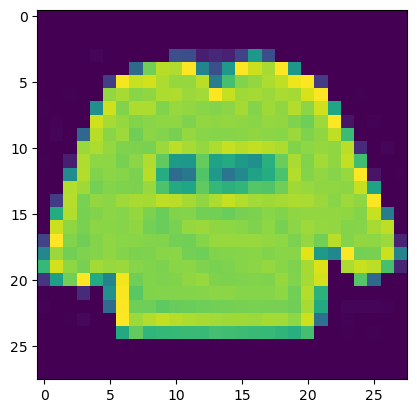

In [25]:
#On exclut la première colonne (les labels) pour constituer un tableau de pixels
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

In [26]:
#On crée des catégories à l'aide du module Keras
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))
#Répartition des données d'entrainement en données d'apprentissage et données de validation
#80% de donnée d'apprentissage et 20% de donnée de validation
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

In [27]:
# On redimensionne les images au format 28*28 et on réalise un scaling sur les données des pixels
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], 
                                          LARGEUR_IMAGE, 
                                          LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0], 
                                    LARGEUR_IMAGE, 
                                    LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

In [28]:
#Preparation des données de tests
observations_test = pnd.read_csv('datas/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], 
                        LARGEUR_IMAGE, 
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

In [29]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

# On spécifie les dimensions de l'image d'entrée
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

# On crée le réseau de neurones couche par couche
reseauNeurone1Convolution = Sequential()

# Ajout de la couche d'entrée
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

#1- Ajout de la couche de convolution comportant
# 32 filtres de de taille 3x3 (Kernel) parcourant l'image
# Une fonction d'activation de type ReLU (Rectified Linear Activation)
# Une image d'entrée de 28px * 28 px 
reseauNeurone1Convolution.add(Conv2D(32, 
                                     kernel_size=(3, 3), 
                                     activation='relu'))

#2- Définition de la fonction de pooling avec une fenêtre de 2px sur 2 px
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

#3- Ajout d'une fonction d'ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

#5 - On transforme en une seule ligne
reseauNeurone1Convolution.add(Flatten())

#6 - Ajout d'un réseau de neurones composé de 128 neurones avec 
# une fonction d'activation de type ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

#7 - Ajout d'un réseau de neurones composé de 10 neurones avec une 
# fonction d'activation de type softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

In [30]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

In [31]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.8132 - loss: 0.5370 - val_accuracy: 0.8612 - val_loss: 0.3955
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.8759 - loss: 0.3535 - val_accuracy: 0.8760 - val_loss: 0.3492
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.8917 - loss: 0.3082 - val_accuracy: 0.8917 - val_loss: 0.3133
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.8992 - loss: 0.2807 - val_accuracy: 0.8928 - val_loss: 0.3008
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.9056 - loss: 0.2615 - val_accuracy: 0.9027 - val_loss: 0.2724
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.9120 - loss: 0.2456 - val_accuracy: 0.9026 - val_loss: 0.2724
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9168 - loss: 0.2329 - val_accuracy: 0.9042 - val_loss: 0.2681
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.9201 - loss: 0.2175 - val_accu

In [32]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.23497039079666138
Précision: 0.9157000184059143


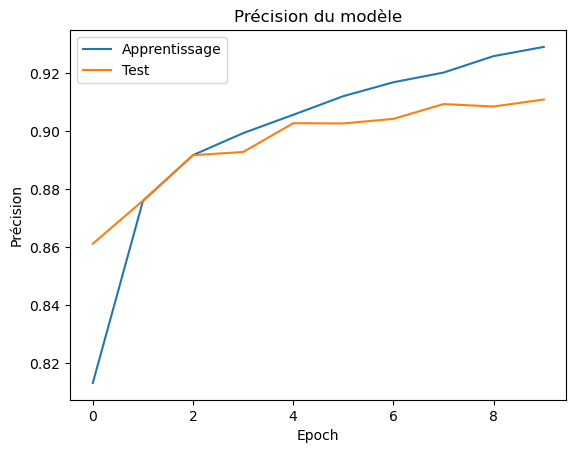

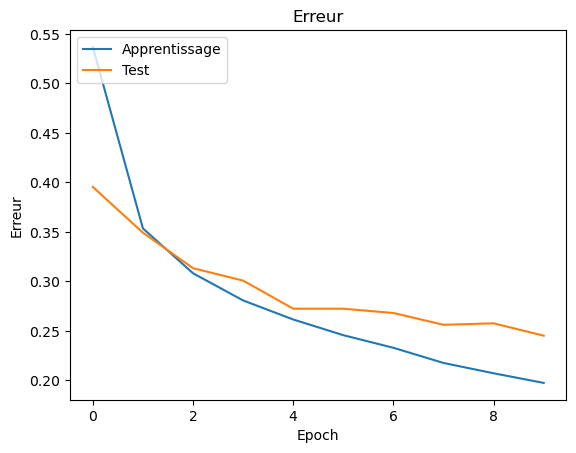

In [33]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
# Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

In [34]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08)

In [35]:
nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation, 
    y_validation,
    batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 64ms/step - accuracy: 0.8283 - loss: 0.4626 - val_accuracy: 0.8450 - val_loss: 0.4170
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.8398 - loss: 0.4488

/home/vscode/.venvs/analyse-image/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8398 - loss: 0.4488 - val_accuracy: 0.8381 - val_loss: 0.4291
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.8477 - loss: 0.4126 - val_accuracy: 0.8520 - val_loss: 0.3957
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8398 - loss: 0.3710 - val_accuracy: 0.8487 - val_loss: 0.4092
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.8540 - loss: 0.3946 - val_accuracy: 0.8575 - val_loss: 0.3876
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8711 - loss: 0.3037 - val_accuracy: 0.8556 - val_loss: 0.3785
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 61ms/step - accuracy: 0.8600 - loss: 0.3756 - val_accuracy: 0.8681 - val_loss: 0.3566
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8750 - loss: 0.3798 - val_accuracy: 0.8697 - val_loss: 0.3620
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.8680 - loss: 0.3583 - val_accuracy: 0

In [36]:
#Sauvegarde du modèle
# Serialisation du modèle 
model_json = reseauNeurone1Convolution.to_json() 
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)
    
# Serialisation des poids
reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !


In [37]:
from keras.layers import BatchNormalization

reseauNeurones4Convolution = Sequential()

reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=dimentionImage))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Flatten())
reseauNeurones4Convolution.add(Dense(512, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(128, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(10, activation='softmax'))

/home/vscode/.venvs/analyse-image/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [38]:
reseauNeurones4Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

historique_apprentissage = reseauNeurones4Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 31s 147ms/step - accuracy: 0.7394 - loss: 0.7445 - val_accuracy: 0.1727 - val_loss: 2.8581
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 27s 142ms/step - accuracy: 0.8401 - loss: 0.4458 - val_accuracy: 0.5276 - val_loss: 1.4234
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 141ms/step - accuracy: 0.8665 - loss: 0.3737 - val_accuracy: 0.8560 - val_loss: 0.3964
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 27s 141ms/step - accuracy: 0.8798 - loss: 0.3339 - val_accuracy: 0.8974 - val_loss: 0.2792
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 27s 141ms/step - accuracy: 0.8897 - loss: 0.3109 - val_accuracy: 0.9042 - val_loss: 0.2679
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 27s 141ms/step - accuracy: 0.8982 - loss: 0.2871 - val_accuracy: 0.9082 - val_loss: 0.2525
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 27s 143ms/step - accuracy: 0.9038 - loss: 0.2690 - val_accuracy: 0.9084 - val_loss: 0.2499
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 27s 141ms/step - accuracy: 0.9087 - loss: 0

In [39]:
evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.21651789546012878
Précision: 0.923799991607666


In [40]:
historique_apprentissage = reseauNeurones4Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 32s 167ms/step - accuracy: 0.8532 - loss: 0.4063 - val_accuracy: 0.8745 - val_loss: 0.3390
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8594 - loss: 0.3741 - val_accuracy: 0.8778 - val_loss: 0.3333
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 28s 152ms/step - accuracy: 0.8658 - loss: 0.3707 - val_accuracy: 0.8803 - val_loss: 0.3241
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8789 - loss: 0.3503 - val_accuracy: 0.8831 - val_loss: 0.3173
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 28s 152ms/step - accuracy: 0.8770 - loss: 0.3451 - val_accuracy: 0.8862 - val_loss: 0.3076
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8789 - loss: 0.3692 - val_accuracy: 0.8838 - val_loss: 0.3106
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 28s 151ms/step - accuracy: 0.8805 - loss: 0.3303 - val_accuracy: 0.8886 - val_loss: 0.2939
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8906 - loss: 0.2841 - 

In [41]:
#Chargement de la description du modèle
fichier_json = open('modele/modele.json', 'r')
modele_json = fichier_json.read()
fichier_json.close()

#Chargement de la description des poids du modèle
from keras.models import model_from_json
modele = model_from_json(modele_json)
#Chargement des poids
modele.load_weights("modele/modele.weights.h5")

In [42]:
#Définition des catégories de classifications
classes = ["Un T-shirt/haut",
           "Un pantalon",
           "Un pull", 
           "Une robe",
           "Un manteau",
           "Des sandales",
           "Une chemise",
           "Des baskets", 
           "Un sac",
           "Des bottes de cheville"]

In [43]:
import numpy as np
from PIL import Image, ImageFilter


def load_and_preprocess_image(image_path, target_size=28, content_size=20):
    """
    Load an image, convert to grayscale, and preprocess for model input.
    
    Args:
        image_path: Path to the input image
        target_size: Size of the output square image (default: 28x28)
        content_size: Size of the resized content within the target (default: 20)
    
    Returns:
        numpy.ndarray: Preprocessed image array ready for model prediction
    """
    image = Image.open(image_path).convert('L')
    resized_img = resize_with_aspect_ratio(image, content_size)
    canvas = create_centered_image(resized_img, target_size)
    normalized_array = normalize_pixels(canvas)
    
    return normalized_array.reshape(1, target_size, target_size, 1)


def resize_with_aspect_ratio(image, target_dimension):
    """
    Resize image maintaining aspect ratio.
    
    Args:
        image: PIL Image object
        target_dimension: Target size for the longest dimension
    
    Returns:
        PIL Image: Resized and sharpened image
    """
    width, height = image.size
    
    if width > height:
        new_width = target_dimension
        new_height = max(1, round(target_dimension * height / width))
    else:
        new_height = target_dimension
        new_width = max(1, round(target_dimension * width / height))
    
    return image.resize((new_width, new_height), Image.LANCZOS).filter(ImageFilter.SHARPEN)


def create_centered_image(image, canvas_size):
    """
    Place image in the center of a white canvas.
    
    Args:
        image: PIL Image to center
        canvas_size: Size of the square canvas
    
    Returns:
        PIL Image: Image centered on white canvas
    """
    canvas = Image.new('L', (canvas_size, canvas_size), 255)
    
    img_width, img_height = image.size
    
    # Calculate centering offsets
    x_offset = (canvas_size - img_width) // 2
    y_offset = (canvas_size - img_height) // 2
    
    canvas.paste(image, (x_offset, y_offset))
    return canvas


def normalize_pixels(image):
    pixels = np.array(image.getdata(), dtype=np.float32)
    # Invert colors (white background to black) and normalize
    return (255 - pixels) / 255.0

In [44]:
image_array = load_and_preprocess_image("image.png")

probabilities = modele.predict(image_array)[0]
predicted_class = np.argmax(probabilities)

print(f"Selon moi l'image est : {classes[predicted_class]}\n")

for i, class_name in enumerate(classes):
    print(f"{class_name}: {probabilities[i] * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Selon moi l'image est : Un pantalon

Un T-shirt/haut: 0.02%
Un pantalon: 98.40%
Un pull: 0.00%
Une robe: 0.03%
Un manteau: 0.00%
Des sandales: 0.20%
Une chemise: 0.03%
Des baskets: 0.00%
Un sac: 1.33%
Des bottes de cheville: 0.00%
